In [1]:
!pip install pyspark


In [2]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("AnalisisAccidentes") \
    .getOrCreate()

print("¡Apache Spark funciona correctamente!")
print("Versión de Spark:", spark.version)


¡Apache Spark funciona correctamente!
Versión de Spark: 4.0.4


In [3]:
from google.colab import files

archivos_subidos = files.upload()


Saving US_Accidents_muestra.csv to US_Accidents_muestra.csv


In [4]:
import os

print(os.path.exists("/content/US_Accidents_muestra.csv"))
print(os.path.getsize("/content/US_Accidents_muestra.csv") / (1024**2), "MB")


True
35.97072982788086 MB


In [5]:
ruta = "/content/US_Accidents_muestra.csv"

df = spark.read.csv(
    ruta,
    header=True,
    inferSchema=True
)

print("Total de registros:", df.count())
print("Total de columnas:", len(df.columns))

df.show(5, truncate=False)


Total de registros: 100000
Total de columnas: 46
+---+-------+--------+-------------------+-------------------+-----------------+------------------+-------+-------+------------+-------------------------------------------------------------------------------------+-------------------------+------------+----------+-----+----------+-------+----------+------------+-------------------+--------------+-------------+-----------+------------+--------------+--------------+---------------+-----------------+-----------------+-------+-----+--------+--------+--------+-------+-------+----------+-------+-----+---------------+--------------+------------+--------------+--------------+-----------------+---------------------+
|ID |Source |Severity|Start_Time         |End_Time           |Start_Lat        |Start_Lng         |End_Lat|End_Lng|Distance(mi)|Description                                                                          |Street                   |City        |County    |State|Zipcode   |Coun

In [6]:
print("Nombres de las columnas:")
print(df.columns)

print("\nTipos de datos:")
df.printSchema()


Nombres de las columnas:
['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat', 'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description', 'Street', 'City', 'County', 'State', 'Zipcode', 'Country', 'Timezone', 'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction', 'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway', 'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal', 'Turning_Loop', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight', 'Astronomical_Twilight']

Tipos de datos:
root
 |-- ID: string (nullable = true)
 |-- Source: string (nullable = true)
 |-- Severity: integer (nullable = true)
 |-- Start_Time: timestamp (nullable = true)
 |-- End_Time: timestamp (nullable = true)
 |-- Start_Lat: double (nullable = true)
 |-- Start_Lng: double (nullable = true)
 |-- End_Lat: string

In [7]:
from pyspark.sql import functions as F

print("Cantidad de filas:", df.count())

print("Filas duplicadas:",
      df.count() - df.dropDuplicates().count())

print("Valores nulos por columna:")

df.select([
    F.sum(
        F.when(F.col(c).isNull(), 1).otherwise(0)
    ).alias(c)
    for c in df.columns
]).show(truncate=False)


Cantidad de filas: 100000
Filas duplicadas: 0
Valores nulos por columna:
+---+------+--------+----------+--------+---------+---------+-------+-------+------------+-----------+------+----+------+-----+-------+-------+--------+------------+-----------------+--------------+-------------+-----------+------------+--------------+--------------+---------------+-----------------+-----------------+-------+----+--------+--------+--------+-------+-------+----------+-------+----+---------------+--------------+------------+--------------+--------------+-----------------+---------------------+
|ID |Source|Severity|Start_Time|End_Time|Start_Lat|Start_Lng|End_Lat|End_Lng|Distance(mi)|Description|Street|City|County|State|Zipcode|Country|Timezone|Airport_Code|Weather_Timestamp|Temperature(F)|Wind_Chill(F)|Humidity(%)|Pressure(in)|Visibility(mi)|Wind_Direction|Wind_Speed(mph)|Precipitation(in)|Weather_Condition|Amenity|Bump|Crossing|Give_Way|Junction|No_Exit|Railway|Roundabout|Station|Stop|Traffic_Calmin

In [8]:
from pyspark.sql import functions as F

# 1. Eliminar filas duplicadas
df_limpio = df.dropDuplicates()

# 2. Eliminar columnas completamente vacías
df_limpio = df_limpio.drop("End_Lat", "End_Lng")

# 3. Convertir las fechas a formato timestamp
df_limpio = (
    df_limpio
    .withColumn("Start_Time", F.to_timestamp("Start_Time"))
    .withColumn("End_Time", F.to_timestamp("End_Time"))
)

# 4. Eliminar registros sin fecha de inicio o gravedad
df_limpio = df_limpio.dropna(
    subset=["Start_Time", "Severity"]
)

# 5. Mostrar resultados
print("Registros antes de la limpieza:", df.count())
print("Registros después de la limpieza:", df_limpio.count())
print("Columnas después de la limpieza:", len(df_limpio.columns))

df_limpio.select(
    "ID", "Severity", "Start_Time", "City",
    "Temperature(F)", "Weather_Condition"
).show(5, truncate=False)


Registros antes de la limpieza: 100000
Registros después de la limpieza: 100000
Columnas después de la limpieza: 44
+-----+--------+-------------------+------------+--------------+-----------------+
|ID   |Severity|Start_Time         |City        |Temperature(F)|Weather_Condition|
+-----+--------+-------------------+------------+--------------+-----------------+
|A-2  |2       |2016-02-08 06:07:59|Reynoldsburg|37.9          |Light Rain       |
|A-273|2       |2016-02-19 04:23:43|Moraine     |39.9          |Clear            |
|A-295|2       |2016-02-19 11:38:14|Dayton      |59.4          |Clear            |
|A-301|3       |2016-02-19 17:41:00|Columbus    |57.0          |Clear            |
|A-498|2       |2016-03-04 11:15:47|Dayton      |32.0          |Overcast         |
+-----+--------+-------------------+------------+--------------+-----------------+
only showing top 5 rows


In [9]:
# A. Accidentes según la gravedad
print("Accidentes por nivel de gravedad:")

df_limpio.groupBy("Severity") \
    .count() \
    .orderBy("Severity") \
    .show()

# B. Accidentes según la hora del día
df_horas = df_limpio.withColumn(
    "Hora",
    F.hour("Start_Time")
)

print("Accidentes por hora:")

df_horas.groupBy("Hora") \
    .count() \
    .orderBy("Hora") \
    .show(24)

# C. Condiciones climáticas más frecuentes
print("Condiciones climáticas más frecuentes:")

df_limpio.groupBy("Weather_Condition") \
    .count() \
    .orderBy(F.desc("count")) \
    .show(10, truncate=False)


Accidentes por nivel de gravedad:
+--------+-----+
|Severity|count|
+--------+-----+
|       1|   98|
|       2|55025|
|       3|44844|
|       4|   33|
+--------+-----+

Accidentes por hora:
+----+-----+
|Hora|count|
+----+-----+
|   0| 2240|
|   1| 1895|
|   2| 1895|
|   3| 1507|
|   4| 1303|
|   5| 1516|
|   6| 1378|
|   7| 2196|
|   8| 3142|
|   9| 5291|
|  10| 7285|
|  11| 7910|
|  12| 6219|
|  13| 5137|
|  14| 5208|
|  15| 4707|
|  16| 5293|
|  17| 5035|
|  18| 6144|
|  19| 6722|
|  20| 7404|
|  21| 4970|
|  22| 3773|
|  23| 1830|
+----+-----+

Condiciones climáticas más frecuentes:
+-----------------+-----+
|Weather_Condition|count|
+-----------------+-----+
|Clear            |57255|
|Overcast         |10255|
|Mostly Cloudy    |8829 |
|Partly Cloudy    |8260 |
|Scattered Clouds |5684 |
|Light Rain       |3211 |
|Haze             |2097 |
|NULL             |1604 |
|Fair             |1039 |
|Rain             |829  |
+-----------------+-----+
only showing top 10 rows


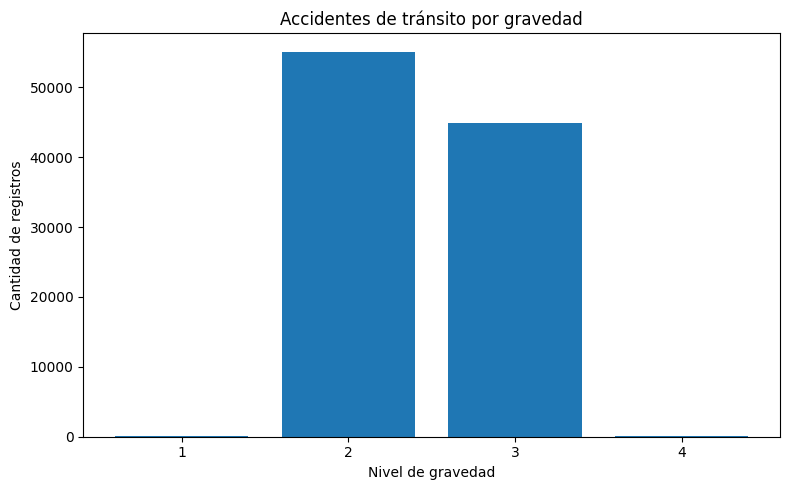

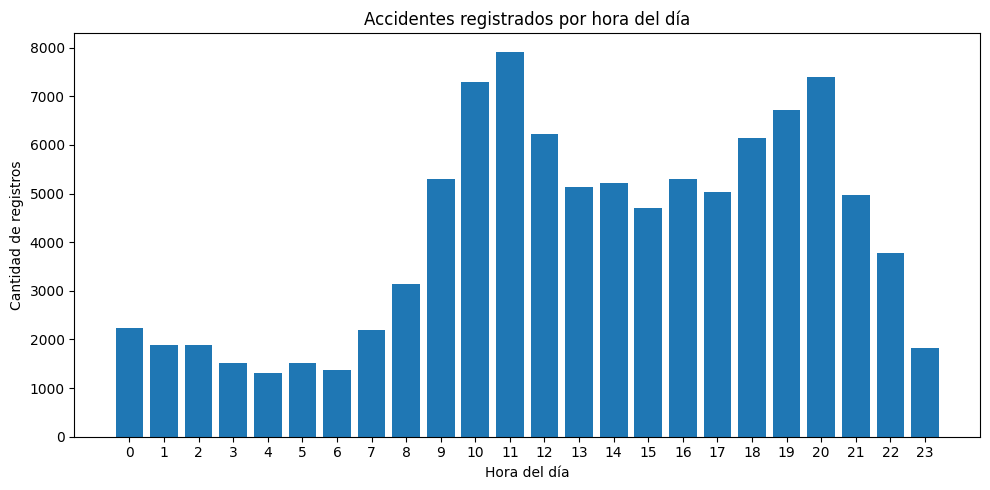

In [10]:
import matplotlib.pyplot as plt

# Resumen de accidentes por gravedad
gravedad_pd = (
    df_limpio.groupBy("Severity")
    .count()
    .orderBy("Severity")
    .toPandas()
)

plt.figure(figsize=(8, 5))
plt.bar(
    gravedad_pd["Severity"].astype(str),
    gravedad_pd["count"]
)
plt.title("Accidentes de tránsito por gravedad")
plt.xlabel("Nivel de gravedad")
plt.ylabel("Cantidad de registros")
plt.tight_layout()
plt.show()

# Resumen de accidentes por hora
horas_pd = (
    df_horas.groupBy("Hora")
    .count()
    .orderBy("Hora")
    .toPandas()
)

plt.figure(figsize=(10, 5))
plt.bar(horas_pd["Hora"], horas_pd["count"])
plt.title("Accidentes registrados por hora del día")
plt.xlabel("Hora del día")
plt.ylabel("Cantidad de registros")
plt.xticks(range(24))
plt.tight_layout()
plt.show()
